In [19]:
import numpy as np
import pandas as pd
from dotenv import load_dotenv
import os
import sys
load_dotenv()
pyAPES_main_folder = os.getenv('pyAPES_main_folder')
sys.path.append(pyAPES_main_folder)
os.chdir(pyAPES_main_folder)

def sinusoidal_soil_temperature(z: np.ndarray, doy: float, T_mean: float, T_amplitude: float,
                                thermal_diffusivity: float = 3e-7,
                                doy_tmax: float = 196.0) -> np.ndarray:
    r"""
    Estimates soil temperature profile from sinusoidal heat-wave propagation theory.

    Assumes the soil surface temperature follows a sinusoidal annual cycle and
    solves the 1D heat conduction analytically:

    .. math::
        T(z,t) = \bar{T} + A_0 \cdot e^{-|z|/d} \cdot
                 \cos\!\left(\frac{2\pi(t - t_{\max})}{365.25} - \frac{|z|}{d}\right)

    where the damping depth :math:`d = \sqrt{\alpha P / \pi}`,
    :math:`\alpha` is the soil thermal diffusivity and :math:`P = 365.25 \times 86400` s.

    References:
        Hillel (1982) Introduction to Soil Physics. Academic Press.

    Args:
        z (array): node elevations relative to soil surface, negative downward [m]
        doy (float): day of year [1..366]
        T_mean (float): annual mean soil temperature [degC]
        T_amplitude (float): annual surface temperature amplitude (half-range) [degC]
        thermal_diffusivity (float): soil thermal diffusivity [m2 s-1], default 3e-6
            (representative of loam at field capacity)
        doy_tmax (float): day of year when surface temperature is at annual maximum,
            default 196.0 (approx. July 15)

    Returns:
        T (array): soil temperature profile at given doy [degC]

    Example::

        import numpy as np
        from pyAPES.soil.heat import sinusoidal_soil_temperature
        dz = np.array([0.05]*20)
        z = dz / 2 - np.cumsum(dz)   # node elevations [m]
        T = sinusoidal_soil_temperature(z, doy=1, T_mean=6.0, T_amplitude=10.0)
    """
    z = np.asarray(z, dtype=float)
    depth = -z  # positive downward [m]

    # annual period [s]
    P = 365.25 * 86400.0
    # damping depth [m]
    d = np.sqrt(thermal_diffusivity * P / np.pi)

    # phase offset from annual maximum [radians]
    phase = 2.0 * np.pi * (doy - doy_tmax) / 365.25

    T = T_mean + T_amplitude * np.exp(-depth / d) * np.cos(phase - depth / d)

    return T

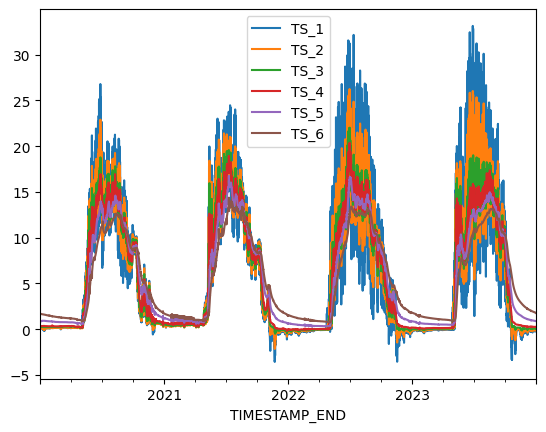

In [ ]:
met = f'{pyAPES_main_folder}/forcing/SE-Deg/SE-Deg_meteo_2020-2023.dat'
meteo = pd.read_csv(met, sep=';', index_col=0, parse_dates=True)
T_mean_all = meteo[['TS_1', 'TS_2', 'TS_3', 'TS_4', 'TS_5', 'TS_6']].mean()
T_mean = T_mean_all.mean()
obs_depths_m = np.array([0.02, 0.05, 0.10, 0.15, 0.30, 0.50])

## Estimate surface `T_amplitude` from soil-temperature observations

For each sensor and calendar year, fit the annual first harmonic to the observed soil temperature. The fitted amplitude is the seasonal amplitude at that sensor depth. Assuming the initializer's sinusoidal conduction model and diffusivity, correct for damping with `A_surface = A_depth * exp(depth / damping_depth)`. The median corrected amplitude across sensors and years is used as a robust summary; compare the individual estimates to assess how well the model's single-wave assumption fits the observations.

Damping depth: 1.74 m
Estimated surface T_amplitude (median across sensors and years): 8.62 degC
Depth-corrected estimates by sensor [degC]:
sensor
TS_1    8.89
TS_2    8.83
TS_3    8.78
TS_4    8.65
TS_5    8.37
TS_6    8.06
Name: T_amplitude_surface_C, dtype: float64


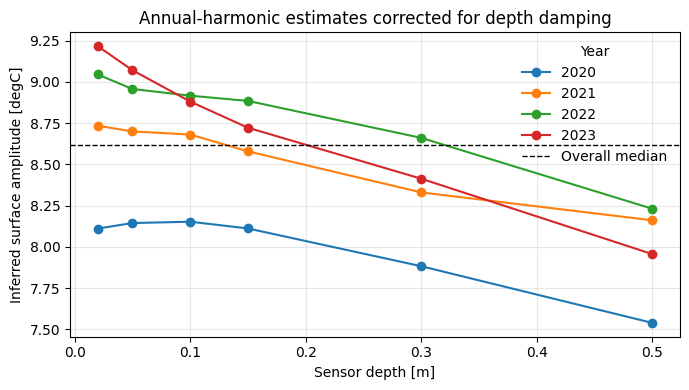

In [22]:
import matplotlib.pyplot as plt

sensor_columns = [f"TS_{index}" for index in range(1, 7)]
thermal_diffusivity = 3e-7
doy_tmax = 196.0
period_days = 365.25
damping_depth = np.sqrt(thermal_diffusivity * period_days * 86400.0 / np.pi)

amplitude_rows = []
for year, yearly_data in meteo[sensor_columns].groupby(meteo.index.year):
    elapsed_days = (yearly_data.index - pd.Timestamp(year=year, month=1, day=1)).total_seconds() / 86400.0
    phase = 2.0 * np.pi * (elapsed_days - doy_tmax) / period_days
    design = np.column_stack([np.ones(len(yearly_data)), np.cos(phase), np.sin(phase)])

    for sensor_index, sensor in enumerate(sensor_columns):
        values = yearly_data[sensor].to_numpy()
        valid = np.isfinite(values)
        coefficients, *_ = np.linalg.lstsq(design[valid], values[valid], rcond=None)
        amplitude_at_depth = np.hypot(coefficients[1], coefficients[2])
        depth = obs_depths_m[sensor_index]
        amplitude_rows.append({
            "year": year,
            "sensor": sensor,
            "depth_m": depth,
            "amplitude_at_depth_C": amplitude_at_depth,
            "T_amplitude_surface_C": amplitude_at_depth * np.exp(depth / damping_depth),
        })

amplitude_estimates = pd.DataFrame(amplitude_rows)
T_amplitude_estimate = amplitude_estimates["T_amplitude_surface_C"].median()
print(f"Damping depth: {damping_depth:.2f} m")
print(f"Estimated surface T_amplitude (median across sensors and years): {T_amplitude_estimate:.2f} degC")
print("Depth-corrected estimates by sensor [degC]:")
print(amplitude_estimates.groupby("sensor")["T_amplitude_surface_C"].median().round(2))

fig, ax = plt.subplots(figsize=(7, 4))
for year, yearly_estimates in amplitude_estimates.groupby("year"):
    ax.plot(yearly_estimates["depth_m"], yearly_estimates["T_amplitude_surface_C"], "o-", label=str(year))
ax.axhline(T_amplitude_estimate, color="black", linestyle="--", linewidth=1, label="Overall median")
ax.set_xlabel("Sensor depth [m]")
ax.set_ylabel("Inferred surface amplitude [degC]")
ax.set_title("Annual-harmonic estimates corrected for depth damping")
ax.grid(True, alpha=0.3)
ax.legend(title="Year", frameon=False)
fig.tight_layout()

## Seasonal soil-temperature initialization

The profile below uses the SE-Deg soil-temperature observations: `T_mean` is the average of the six sensor means, and `T_amplitude` is the median surface-amplitude estimate from the annual-harmonic fits above. The surface amplitude is inferred by correcting sensor amplitudes for depth damping using the assumed thermal diffusivity `3e-7 m2 s-1`; the peak day remains set to day 196 (July 15). Because the corrected amplitudes vary with sensor depth, treat this as an approximate initialization rather than a unique fitted parameter.

Using T_mean = 5.59 degC and T_amplitude = 8.62 degC
Damping depth: 1.74 m
Temperature-wave amplitude at 1 damping depth: 3.17 degC
Approximate phase lag per damping depth: 58.1 days


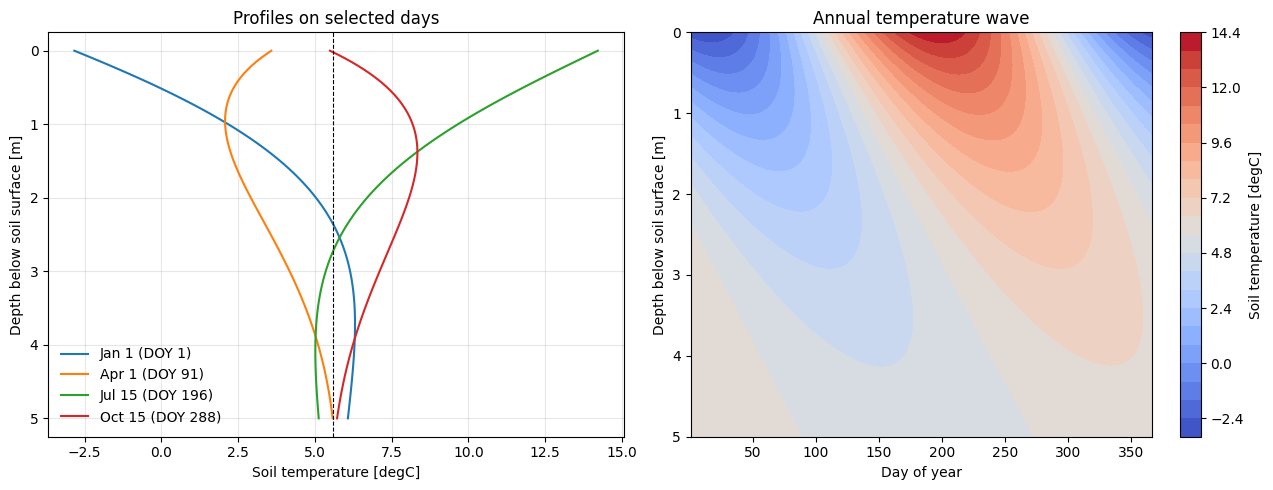

In [24]:
import matplotlib.pyplot as plt

T_mean = float(T_mean_all.mean())
T_amplitude = float(T_amplitude_estimate)
thermal_diffusivity = 3e-7
doy_tmax = 196.0

print(f"Using T_mean = {T_mean:.2f} degC and T_amplitude = {T_amplitude:.2f} degC")
depths = np.linspace(0.0, 5.0, 101)  # Positive downward [m], 5 cm spacing
days = np.arange(1.0, 367.0)
damping_depth = np.sqrt(thermal_diffusivity * 365.25 * 86400.0 / np.pi)

temperature_by_day = np.column_stack([
    sinusoidal_soil_temperature(
        z=-depths,
        doy=day,
        T_mean=T_mean,
        T_amplitude=T_amplitude,
        thermal_diffusivity=thermal_diffusivity,
        doy_tmax=doy_tmax,
    )
    for day in days
])

seasonal_profiles = {
    "Jan 1 (DOY 1)": 1.0,
    "Apr 1 (DOY 91)": 91.0,
    "Jul 15 (DOY 196)": 196.0,
    "Oct 15 (DOY 288)": 288.0,
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for label, day in seasonal_profiles.items():
    profile = sinusoidal_soil_temperature(
        z=-depths,
        doy=day,
        T_mean=T_mean,
        T_amplitude=T_amplitude,
        thermal_diffusivity=thermal_diffusivity,
        doy_tmax=doy_tmax,
    )
    axes[0].plot(profile, depths, label=label)

axes[0].axvline(T_mean, color="black", linewidth=0.8, linestyle="--")
axes[0].set_xlabel("Soil temperature [degC]")
axes[0].set_ylabel("Depth below soil surface [m]")
axes[0].set_title("Profiles on selected days")
axes[0].invert_yaxis()
axes[0].grid(True, alpha=0.3)
axes[0].legend(frameon=False)

image = axes[1].contourf(days, depths, temperature_by_day, levels=25, cmap="coolwarm")
axes[1].set_xlabel("Day of year")
axes[1].set_ylabel("Depth below soil surface [m]")
axes[1].set_title("Annual temperature wave")
axes[1].invert_yaxis()
fig.colorbar(image, ax=axes[1], label="Soil temperature [degC]")
fig.tight_layout()

phase_lag_days = 365.25 / (2.0 * np.pi)
print(f"Damping depth: {damping_depth:.2f} m")
print(f"Temperature-wave amplitude at 1 damping depth: {T_amplitude * np.exp(-1):.2f} degC")
print(f"Approximate phase lag per damping depth: {phase_lag_days:.1f} days")